# 01 — Análise exploratória: Give Me Some Credit

> Esta análise vem **antes** de qualquer modelo, relatório ou documento do projeto. Ela parte
> de duas fontes só: o **enunciado do Tech Challenge** (o problema) e o **arquivo de dados**
> (todo o resto). Cada afirmação daqui em diante é medida numa célula deste notebook; o que o
> dado não permite medir aparece como limite, na seção 10, e não como premissa.
>
> Para reexecutar: `poetry install --with notebooks` e depois `make eda`.

## 0. O problema

*Fonte: enunciado do Tech Challenge, Fase 4.*

Uma fintech de concessão de crédito tem um modelo de *credit scoring* em produção. Depois de
mudanças na economia (inflação, novos perfis de cliente), a diretoria suspeita que o modelo
está decidindo errado e degradando em silêncio.

Antes de modelar qualquer coisa, a base precisa responder:

1. **O dado chega íntegro?** Ausências, duplicatas, valores impossíveis — e se os defeitos
   são independentes ou um evento só.
2. **O que a base é, e o que ela não é?** Horizonte do alvo, existência de tempo, de
   identificador, de variáveis demográficas.
3. **O que a limpeza tira da base?** E se quem sai é parecido com quem fica.
4. **Como é o alvo?** Proporção, e o que isso faz com as métricas.
5. **Quais variáveis carregam sinal sobre a inadimplência**, com que forma e com que força?
6. **Como o risco varia com a idade**, a única variável demográfica, e por quais caminhos?

## 1. O arquivo: o que ele diz sobre si mesmo

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.metrics import roc_auc_score

from credito.config import get_settings
from credito.data.arff import ler_arff
from credito.data.prepare import limpar, separar
from credito.schema import ALVO, ALVO_ORIGINAL, COLUNAS_DE_ATRASO, FEATURES

pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 30

# Paleta: azul e laranja são os dois primeiros slots de uma paleta categórica validada para
# daltonismo; tinta e grade em cinzas neutros. Um único gráfico nunca usa mais de duas cores.
AZUL, LARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, GRADE, FUNDO = "#0b0b0b", "#52514e", "#e5e4df", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "figure.facecolor": FUNDO,
        "axes.facecolor": FUNDO,
        "axes.edgecolor": TINTA_2,
        "axes.labelcolor": TINTA_2,
        "axes.titlecolor": TINTA,
        "axes.titlesize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.grid.axis": "y",
        "grid.color": GRADE,
        "grid.linewidth": 0.8,
        "xtick.color": TINTA_2,
        "ytick.color": TINTA_2,
        "font.size": 10,
        "legend.frameon": False,
    }
)

settings = get_settings()

In [2]:
cabecalho = []
with open(settings.dataset_path, encoding="utf-8") as arquivo:
    for linha in arquivo:
        if linha.upper().startswith("@DATA"):
            break
        if linha.strip() not in ("", "%"):
            cabecalho.append(linha.rstrip())
print("\n".join(cabecalho))

% This dataset was curated for [TabArena](https://tabarena.ai/) by the TabArena team
% as part of the [TabArena Tabular ML IID Study](https://tabarena.ai/data-tabular-ml-iid-study).
% For more details on the study, see our [paper](https://tabarena.ai/paper-tabular-ml-iid-study).
% **Dataset Focus**: This dataset shall be used for evaluating predictive machine
% learning models for independent and identically distributed tabular data. The
% intended task is classification.
% ---
% #### Dataset Metadata
% - **Licence:** Public
% - **Original Data Source:** https://www.kaggle.com/competitions/GiveMeSomeCredit
% - **Reference (please cite)**: Credit Fusion and Will Cukierski. Give Me Some Credit. https://kaggle.com/competitions/GiveMeSomeCredit, 2011. Kaggle.
% - **Dataset Year:** 2011
% - **Dataset Description:** see the reference and the original data source for details.
% #### Curation comments by the TabArena team (for code see the [page of the study](https://tabarena.ai/data-tabular-m

O cabeçalho do arquivo traz a origem — a competição *Give Me Some Credit* (Kaggle, 2011),
redistribuída pelo OpenML com curadoria do TabArena, que **renomeou o alvo** — e o tipo de
cada coluna. Ele **não descreve o significado de nenhuma coluna**. Três consequências valem
para o resto da análise:

1. **O horizonte do alvo está no próprio nome**: `FinancialDistressNextTwoYears`. O rótulo
   descreve o que aconteceu nos dois anos **seguintes** à observação das variáveis. Quem
   pede crédito hoje só tem rótulo dois anos depois.
2. **Não há coluna de data nem identificador** (a tabela abaixo confere): não é possível
   ordenar as linhas no tempo, separar treino e teste por período, medir a defasagem do
   rótulo, nem ligar uma linha a uma pessoa.
3. **O significado das colunas vem de fora do arquivo.** As descrições do dicionário abaixo
   são traduzidas do dicionário de dados publicado na página da competição no Kaggle. Onde o
   dado contradiz a descrição (seções 2.3 e 6.1), vale o dado.

In [3]:
NOMES = {
    "RevolvingUtilizationOfUnsecuredLines": "uso_rotativo",
    "age": "idade",
    "NumberOfTime30-59DaysPastDueNotWorse": "atraso_30_59",
    "DebtRatio": "razao_divida",
    "MonthlyIncome": "renda_mensal",
    "NumberOfOpenCreditLinesAndLoans": "linhas_abertas",
    "NumberOfTimes90DaysLate": "atraso_90",
    "NumberRealEstateLoansOrLines": "imobiliario",
    "NumberOfTime60-89DaysPastDueNotWorse": "atraso_60_89",
    "NumberOfDependents": "dependentes",
}
DESCRICAO = {
    "RevolvingUtilizationOfUnsecuredLines": (
        "saldo em cartão e crédito pessoal (sem garantia) dividido pelo limite total",
        "proporção",
    ),
    "age": ("idade do tomador, em anos", "inteiro"),
    "NumberOfTime30-59DaysPastDueNotWorse": (
        "vezes com atraso de 30 a 59 dias nos últimos 2 anos",
        "contagem",
    ),
    "DebtRatio": ("pagamentos mensais de dívida e custo de vida dividido pela renda", "razão"),
    "MonthlyIncome": ("renda mensal declarada", "moeda"),
    "NumberOfOpenCreditLinesAndLoans": (
        "empréstimos parcelados e linhas de crédito abertas",
        "contagem",
    ),
    "NumberOfTimes90DaysLate": ("vezes com atraso de 90 dias ou mais", "contagem"),
    "NumberRealEstateLoansOrLines": ("financiamentos imobiliários e home equity", "contagem"),
    "NumberOfTime60-89DaysPastDueNotWorse": (
        "vezes com atraso de 60 a 89 dias nos últimos 2 anos",
        "contagem",
    ),
    "NumberOfDependents": ("dependentes na família, excluindo o próprio", "contagem"),
}
dicionario = pd.DataFrame(
    [(c, NOMES[c], *DESCRICAO[c]) for c in FEATURES],
    columns=["coluna original", "nome curto", "descrição", "tipo"],
)
dicionario.loc[len(dicionario)] = [
    ALVO_ORIGINAL,
    ALVO,
    "dificuldade financeira grave (90+ dias de atraso) nos 2 anos seguintes",
    "binário",
]
display(dicionario.style.hide(axis="index"))

coluna original,nome curto,descrição,tipo
RevolvingUtilizationOfUnsecuredLines,uso_rotativo,saldo em cartão e crédito pessoal (sem garantia) dividido pelo limite total,proporção
age,idade,"idade do tomador, em anos",inteiro
NumberOfTime30-59DaysPastDueNotWorse,atraso_30_59,vezes com atraso de 30 a 59 dias nos últimos 2 anos,contagem
DebtRatio,razao_divida,pagamentos mensais de dívida e custo de vida dividido pela renda,razão
MonthlyIncome,renda_mensal,renda mensal declarada,moeda
NumberOfOpenCreditLinesAndLoans,linhas_abertas,empréstimos parcelados e linhas de crédito abertas,contagem
NumberOfTimes90DaysLate,atraso_90,vezes com atraso de 90 dias ou mais,contagem
NumberRealEstateLoansOrLines,imobiliario,financiamentos imobiliários e home equity,contagem
NumberOfTime60-89DaysPastDueNotWorse,atraso_60_89,vezes com atraso de 60 a 89 dias nos últimos 2 anos,contagem
NumberOfDependents,dependentes,"dependentes na família, excluindo o próprio",contagem


In [4]:
bruto = ler_arff(settings.dataset_path)
y_bruto = (bruto[ALVO_ORIGINAL] == "Yes").astype(int)
print(f"{len(bruto):,} linhas x {bruto.shape[1]} colunas\n")
tipos_no_arquivo = dict(
    linha.split(maxsplit=2)[1:3] for linha in cabecalho if linha.upper().startswith("@ATTRIBUTE")
)
tipos = pd.DataFrame(
    {
        "tipo no arquivo": pd.Series(tipos_no_arquivo),
        "tipo carregado": bruto.dtypes.astype(str),
        "valores distintos": bruto.nunique(),
        "único por linha?": bruto.nunique() == len(bruto),
    }
)
display(tipos)
display(bruto.head())

150,000 linhas x 11 colunas



,tipo no arquivo,tipo carregado,valores distintos,único por linha?
FinancialDistressNextTwoYears,"{No, Yes}",object,2,False
RevolvingUtilizationOfUnsecuredLines,REAL,float64,125728,False
age,INTEGER,int64,86,False
NumberOfTime30-59DaysPastDueNotWorse,INTEGER,int64,16,False
DebtRatio,REAL,float64,114194,False
MonthlyIncome,REAL,float64,13594,False
NumberOfOpenCreditLinesAndLoans,INTEGER,int64,58,False
NumberOfTimes90DaysLate,INTEGER,int64,19,False
NumberRealEstateLoansOrLines,INTEGER,int64,28,False
NumberOfTime60-89DaysPastDueNotWorse,INTEGER,int64,13,False


,FinancialDistressNextTwoYears,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,No,0.0297,57,0,0.2832,"10,121.0000",7,0,1,0,0.0000
1,No,0.0000,57,0,0.1426,"7,750.0000",9,0,1,0,0.0000
2,No,0.0366,48,0,0.2363,"6,000.0000",6,0,2,0,3.0000
3,No,1.0183,41,0,0.1631,"4,958.0000",4,0,0,0,0.0000
4,No,1.0088,49,0,"3,942.0000",NaN,10,0,1,0,0.0000


O formato ARFF tem um tipo próprio para datas (`DATE`) e nenhuma coluna o usa: todas são
`REAL`, `INTEGER` ou a categoria do alvo. E nenhuma é única por linha: a base é um **retrato sem tempo e sem
identificador**. Das dez variáveis de entrada, **uma só é demográfica** (`age`); as outras
nove descrevem renda, dívida e comportamento de crédito.

## 2. Qualidade dos dados (arquivo bruto)

Esta seção olha o arquivo **como ele chega**, antes de qualquer limpeza. As regras de limpeza
da seção 2.4 saem daqui.

### 2.1 Valores ausentes

In [5]:
nulos = pd.DataFrame(
    {"nulos": bruto[list(FEATURES)].isna().sum(), "%": bruto[list(FEATURES)].isna().mean() * 100}
).rename(index=NOMES)
display(nulos[nulos["nulos"] > 0])

sem_renda = bruto["MonthlyIncome"].isna()
sem_dependentes = bruto["NumberOfDependents"].isna()
display(
    pd.crosstab(
        sem_renda.map({True: "renda ausente", False: "renda presente"}),
        sem_dependentes.map({True: "dependentes ausente", False: "dependentes presente"}),
        margins=True,
        margins_name="total",
    )
)

,nulos,%
renda_mensal,29731,19.8207
dependentes,3924,2.6160


NumberOfDependents,dependentes ausente,dependentes presente,total
MonthlyIncome,,,
renda ausente,3924,25807,29731
renda presente,0,120269,120269
total,3924,146076,150000


Duas colunas têm ausência: renda (19,82%) e dependentes (2,62%). A tabela cruzada mostra que
**não são duas ausências independentes**: as 3.924 linhas sem dependentes estão, todas, entre
as linhas sem renda — não existe nenhuma linha com renda presente e dependentes ausente. É um
mesmo evento de coleta com dois sintomas.

Consequência prática: imputar as duas colunas separadamente, como se cada uma tivesse falhado
por conta própria, trataria como acaso algo que tem um padrão.

### 2.2 Duplicatas e rótulos conflitantes

In [6]:
features = list(FEATURES)
dup_linha = bruto.duplicated().sum()
dup_features = bruto.duplicated(subset=features).sum()
grupos = bruto.assign(_y=y_bruto).groupby(features, dropna=False)["_y"].nunique()
conflitos = int((grupos > 1).sum())
print(f"linhas idênticas por inteiro (alvo incluído): {dup_linha:,}")
print(f"linhas repetidas só nas features:             {dup_features:,}")
print(f"grupos de features idênticas com alvo diferente: {conflitos:,}")

linhas idênticas por inteiro (alvo incluído): 609
linhas repetidas só nas features:             646
grupos de features idênticas com alvo diferente: 37


646 linhas repetem outra nas variáveis de entrada; 609 delas são cópias exatas, alvo incluído.
A diferença — **37 grupos** — é mais interessante: o mesmo perfil, valor a valor, com desfechos
opostos (um inadimpliu, o outro não). É pouco (0,02% da base) e não muda o modelo, mas é um
lembrete útil: existe ruído que nenhuma combinação destas dez variáveis explica. A limpeza
mantém a primeira ocorrência de cada grupo.

### 2.3 Valores impossíveis: sentinelas, idade e razão de dívida

In [7]:
for coluna in COLUNAS_DE_ATRASO:
    acima = bruto.loc[bruto[coluna] > 20, coluna].value_counts().sort_index()
    print(f"{NOMES[coluna]:>13}: valores acima de 20 -> {dict(acima)}")
print(
    f"\nidade: mínimo {bruto['age'].min()}, máximo {bruto['age'].max()}, "
    f"abaixo de 18: {(bruto['age'] < 18).sum()}"
)

quantis = [0.5, 0.9, 0.95, 0.99]
razao = pd.DataFrame(
    {
        "renda presente": bruto.loc[~sem_renda, "DebtRatio"].quantile(quantis),
        "renda ausente": bruto.loc[sem_renda, "DebtRatio"].quantile(quantis),
    }
)
razao.index = [f"p{int(q * 100)}" for q in quantis]
razao.loc["% acima de 10"] = [
    (bruto.loc[~sem_renda, "DebtRatio"] > 10).mean() * 100,
    (bruto.loc[sem_renda, "DebtRatio"] > 10).mean() * 100,
]
display(razao)

 atraso_30_59: valores acima de 20 -> {96: np.int64(5), 98: np.int64(264)}
    atraso_90: valores acima de 20 -> {96: np.int64(5), 98: np.int64(264)}
 atraso_60_89: valores acima de 20 -> {96: np.int64(5), 98: np.int64(264)}

idade: mínimo 0, máximo 109, abaixo de 18: 1


,renda presente,renda ausente
p50,0.2960,"1,159.0000"
p90,0.7631,"3,785.0000"
p95,1.1288,"4,902.5000"
p99,661.8200,"8,084.5000"
% acima de 10,1.7511,90.0441


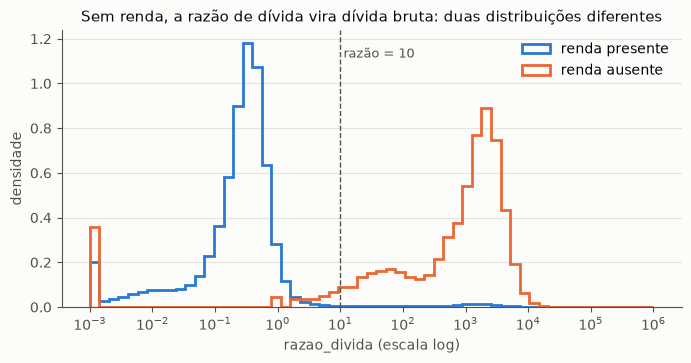

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(-3, 6, 60)
for mascara, cor, rotulo in [
    (~sem_renda, AZUL, "renda presente"),
    (sem_renda, LARANJA, "renda ausente"),
]:
    valores = np.log10(bruto.loc[mascara, "DebtRatio"].clip(lower=1e-3))
    ax.hist(valores, bins=bins, density=True, histtype="step", linewidth=2, color=cor, label=rotulo)
ax.axvline(1, color=TINTA_2, linestyle="--", linewidth=1)
ax.text(1.05, ax.get_ylim()[1] * 0.9, "razão = 10", color=TINTA_2, fontsize=9)
ax.set_xticks(range(-3, 7), [f"$10^{{{k}}}$" for k in range(-3, 7)])
ax.set_xlabel("razao_divida (escala log)")
ax.set_ylabel("densidade")
ax.set_title("Sem renda, a razão de dívida vira dívida bruta: duas distribuições diferentes")
ax.legend()
plt.show()

In [9]:
sentinela = bruto[list(COLUNAS_DE_ATRASO)].gt(20)
print(
    f"linhas com sentinela em alguma coluna de atraso: {sentinela.any(axis=1).sum()}, "
    f"nas três ao mesmo tempo: {sentinela.all(axis=1).sum()}"
)
pearson = pd.DataFrame(
    {
        "com sentinelas (bruto)": bruto[list(COLUNAS_DE_ATRASO)]
        .corr()
        .where(np.triu(np.ones((3, 3), dtype=bool), k=1))
        .stack(),
        "sem sentinelas": bruto.loc[~sentinela.any(axis=1), list(COLUNAS_DE_ATRASO)]
        .corr()
        .where(np.triu(np.ones((3, 3), dtype=bool), k=1))
        .stack(),
    }
).rename(index=NOMES)
display(pearson)

linhas com sentinela em alguma coluna de atraso: 269, nas três ao mesmo tempo: 269


com sentinelas (bruto)  sem sentinelas
atraso_30_59 atraso_90                     0.9836          0.2181
             atraso_60_89                  0.9870          0.3059
atraso_90    atraso_60_89                  0.9928          0.2946

Três defeitos do tipo "o valor tem o tipo certo e é impossível":

- **Sentinelas 96 e 98 nas colunas de atraso.** São códigos de "não disponível" herdados da
  coleta, não contagens — ninguém atrasa 98 vezes em dois anos. Aparecem em 269 linhas, e são
  **as mesmas linhas nas três colunas**. O estrago vai além das próprias linhas: a correlação
  de Pearson entre as colunas de atraso salta de cerca de 0,2–0,3 para 0,98–0,99. **0,18% das
  linhas fabricam uma multicolinearidade quase perfeita** — quem olhasse a matriz de
  correlação do bruto concluiria que as três colunas são redundantes e descartaria duas.
- **Idade 0.** Uma linha; erro de digitação.
- **Razão de dívida sem renda.** Com renda declarada, o p95 é 1,13; sem renda, a *mediana* é
  1.159 e 90% passam de 10. O gráfico mostra duas populações que mal se tocam: sem o
  denominador, o campo guarda a dívida bruta. Não é outlier — é **outra unidade de medida na
  mesma coluna**. (O pico em $10^{-3}$ são os zeros, deslocados para caber na escala log.)

A seção 2.4 transforma cada um desses defeitos numa regra.

### 2.4 Das evidências às regras de limpeza

Cada regra abaixo é a resposta a um defeito medido nas seções 2.1 a 2.3, e cada corte sai do
dado:

In [10]:
for coluna in COLUNAS_DE_ATRASO:
    legitimos = bruto.loc[bruto[coluna] < 96, coluna]
    vazio = sorted(set(range(int(legitimos.max()) + 1, 96)) & set(bruto[coluna].unique()))
    print(
        f"{NOMES[coluna]:>13}: maior valor abaixo de 96 = {legitimos.max()}; "
        f"valores entre ele e 96: {vazio or 'nenhum'}"
    )
idades = np.sort(bruto["age"].unique())
print(f"\nidade: menores valores {idades[:3].tolist()}, maiores {idades[-3:].tolist()}")
p95_com_renda = bruto.loc[~sem_renda, "DebtRatio"].quantile(0.95)
print(f"razão de dívida, p95 de quem declara renda: {p95_com_renda:.2f}")

 atraso_30_59: maior valor abaixo de 96 = 13; valores entre ele e 96: nenhum
    atraso_90: maior valor abaixo de 96 = 17; valores entre ele e 96: nenhum
 atraso_60_89: maior valor abaixo de 96 = 11; valores entre ele e 96: nenhum

idade: menores valores [0, 21, 22], maiores [105, 107, 109]
razão de dívida, p95 de quem declara renda: 1.13


| Regra | Defeito que ela resolve | De onde sai o corte |
|---|---|---|
| sem repetição nas variáveis de entrada | 646 repetidas, 37 com rótulo conflitante (2.2) | — |
| renda presente e não negativa | razão de dívida perde o denominador (2.3) | — |
| dependentes presente e não negativo | ausência no mesmo evento da renda (2.1) | — |
| idade de pelo menos 18 | idade 0 (2.3) | maioridade; no dado não existe nada entre 1 e 20 anos, então o corte não afeta ninguém além do 0 |
| atraso de no máximo 20 em cada coluna | sentinelas 96/98 (2.3) | o maior atraso legítimo é 17 e não existe nada entre 18 e 95: qualquer corte nessa faixa separa exatamente os sentinelas |
| razão de dívida entre 0 e 10 | razão sem denominador que sobra mesmo com renda (2.3) | cerca de 9 vezes o p95 de quem declara renda (1,13): tolera o atípico e barra quem guarda dívida bruta no campo |
| demais colunas não nulas | — | exigência estrutural; mede 0 abaixo |

As regras rodam em sequência, e cada contagem é sobre o que sobrou da anterior — a soma é o
total de linhas perdidas, sem dupla contagem.

In [11]:
IDADE_MINIMA, ATRASO_MAXIMO, RAZAO_DIVIDA_MAXIMA = 18, 20, 10.0

base = bruto.drop(columns=ALVO_ORIGINAL).assign(**{ALVO: y_bruto})
descartes = {"duplicata": int(base.duplicated(subset=features).sum())}
base = base.drop_duplicates(subset=features)


# Em sequência: cada regra vê só o que sobrou da anterior. `ge` e `between` devolvem False
# para nulo, então "não cumpre a exigência" já inclui o valor ausente.
regras = [
    ("renda ausente ou negativa", lambda d: ~d["MonthlyIncome"].ge(0)),
    ("dependentes ausente ou negativo", lambda d: ~d["NumberOfDependents"].ge(0)),
    ("idade abaixo de 18", lambda d: d["age"] < IDADE_MINIMA),
    ("sentinela de atraso", lambda d: d[list(COLUNAS_DE_ATRASO)].gt(ATRASO_MAXIMO).any(axis=1)),
    ("razão de dívida fora de [0, 10]", lambda d: ~d["DebtRatio"].between(0, RAZAO_DIVIDA_MAXIMA)),
    ("outra coluna nula", lambda d: d[list(FEATURES)].isna().any(axis=1)),
]
for motivo, regra in regras:
    mascara = regra(base)
    descartes[motivo] = int(mascara.sum())
    base = base.loc[~mascara]
referencia = base[[ALVO, *FEATURES]].reset_index(drop=True)

display(pd.Series(descartes, name="linhas descartadas").to_frame())
print(
    f"{len(bruto):,} linhas no bruto -> {len(referencia):,} na base limpa "
    f"({len(referencia) / len(bruto):.2%} retidas)"
)

# Conferência: o código de limpeza do pacote `credito` precisa produzir exatamente esta base,
# para que os próximos notebooks e o treino partam do mesmo dado que esta análise descreve.
assert referencia.equals(limpar(bruto)[0]), "a limpeza do pacote diverge das regras acima"

,linhas descartadas
duplicata,646
renda ausente ou negativa,29186
dependentes ausente ou negativo,0
idade abaixo de 18,1
sentinela de atraso,144
"razão de dívida fora de [0, 10]",2106
outra coluna nula,0


150,000 linhas no bruto -> 117,917 na base limpa (78.61% retidas)


O maior descarte, de longe, é o de renda ausente: perto de um quinto do arquivo. Antes de
aceitar isso, a seção 3 pergunta quem são essas pessoas.

## 3. Quem o descarte tira da base: viés de seleção

A limpeza descarta quem não declarou renda. Antes de aceitar isso, vale perguntar: **essas
pessoas são parecidas com as que ficam?** Se não forem, o modelo aprende sobre uma população
diferente da que vai pontuar.

In [12]:
def wilson(sucessos: int, n: int, z: float = 1.96) -> tuple[float, float]:
    # Intervalo de confiança de Wilson para uma proporção: bem-comportado mesmo com poucos
    # eventos, ao contrário do intervalo normal.
    if n == 0:
        return (np.nan, np.nan)
    p = sucessos / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    meia = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - meia, centro + meia


def perfil(mascara: pd.Series) -> dict[str, float]:
    parte = bruto.loc[mascara]
    alvo = y_bruto.loc[mascara]
    baixo, alto = wilson(int(alvo.sum()), len(alvo))
    algum_atraso = (parte[list(COLUNAS_DE_ATRASO)].clip(upper=20).sum(axis=1) > 0).mean()
    return {
        "n": len(parte),
        "inadimplência": alvo.mean(),
        "IC95 inferior": baixo,
        "IC95 superior": alto,
        "idade mediana": parte["age"].median(),
        "% com algum atraso": algum_atraso * 100,
        "uso_rotativo mediano": parte["RevolvingUtilizationOfUnsecuredLines"].median(),
        "linhas_abertas medianas": parte["NumberOfOpenCreditLinesAndLoans"].median(),
    }


comparacao = pd.DataFrame(
    {"renda presente": perfil(~sem_renda), "renda ausente": perfil(sem_renda)}
)
display(comparacao)

tabela = pd.crosstab(sem_renda, y_bruto)
qui2, p_valor, *_ = stats.chi2_contingency(tabela)
print(f"qui-quadrado = {qui2:.1f}, p = {p_valor:.2e}")

,renda presente,renda ausente
n,"120,269.0000","29,731.0000"
inadimplência,0.0695,0.0561
IC95 inferior,0.0681,0.0536
IC95 superior,0.0709,0.0588
idade mediana,51.0000,57.0000
% com algum atraso,21.1501,16.5686
uso_rotativo mediano,0.1773,0.0817
linhas_abertas medianas,8.0000,6.0000


qui-quadrado = 67.9, p = 1.73e-16

**Não são parecidas.** Quem não declarou renda inadimple **menos**: 5,61% (IC 95% de 5,36% a
5,88%) contra 6,95% (6,81% a 7,09%). Os intervalos não se sobrepõem, e o qui-quadrado dá
p ≈ 2·10⁻¹⁶. O perfil inteiro é diferente: mais velhos (mediana de 57 contra 51 anos), usam
menos da metade do rotativo (0,08 contra 0,18), atrasam menos (16,6% contra 21,2% com algum
atraso) e têm menos linhas de crédito abertas. É compatível com aposentados ou com renda
informal — hipótese, que esta base não permite verificar.

Três consequências:

1. **A Referência sub-representa um segmento de risco menor e mais velho.** O modelo aprende
   sobre uma população um pouco mais jovem e mais arriscada do que a que pede crédito.
2. **Se a mesma regra valer na entrada do modelo, essas pessoas nunca recebem score.** Para o
   negócio, é um segmento bom recusado por formulário; para a equidade, o bloqueio pesa mais
   sobre os mais velhos — interseção direta com a única variável demográfica da base.
3. **Descartar é necessário para que a razão de dívida signifique a mesma coisa em toda a
   base (seção 2.3), mas não é neutro.** Tratar esse grupo (imputação ou modelo próprio) deixa de ser "preencher dado
   faltante" e passa a ser atender um segmento.

## 4. O alvo e a base limpa

A partir daqui a análise usa a **base limpa** da seção 2.4 e, para tudo que relaciona
variável com alvo, **só a partição de treino** (70% da base, estratificada pelo alvo, semente
42). Olhar a relação com o alvo na validação ou no teste e depois tomar decisão de modelagem
com base nisso vazaria informação para a avaliação: o teste deixaria de ser um teste.

In [13]:
particoes = separar(
    referencia,
    test_size=settings.test_size,
    validation_size=settings.validation_size,
    seed=settings.random_seed,
)
treino = particoes["treino"]

prevalencia = pd.DataFrame(
    {
        "linhas": [len(bruto), len(referencia), *(len(p) for p in particoes.values())],
        "inadimplentes": [
            int(y_bruto.sum()),
            int(referencia[ALVO].sum()),
            *(int(p[ALVO].sum()) for p in particoes.values()),
        ],
    },
    index=["bruto", "referência", *particoes.keys()],
)
prevalencia["taxa"] = prevalencia["inadimplentes"] / prevalencia["linhas"]
display(prevalencia)
print(f"acurácia de quem responde 'adimplente' para todo mundo: {1 - treino[ALVO].mean():.4f}")

,linhas,inadimplentes,taxa
bruto,150000,10026,0.0668
referência,117917,8186,0.0694
treino,70749,4912,0.0694
validacao,23584,1637,0.0694
teste,23584,1637,0.0694


acurácia de quem responde 'adimplente' para todo mundo: 0.9306


A taxa de inadimplência sobe de 6,68% no bruto para 6,94% na Referência — a limpeza tirou
proporcionalmente mais adimplentes, coerente com a seção 3. As partições são estratificadas e
mantêm 6,94% em todas.

**Por que acurácia não serve:** responder "adimplente" para todo mundo acerta 93,06% e não
identifica nenhum inadimplente. Qualquer modelo deve ser lido contra essa linha de base, e a
AUC-PR contra a prevalência (0,0694), que é a AUC-PR de um ordenamento aleatório.

## 5. Distribuição de cada variável (treino)

In [14]:
resumo = treino[list(FEATURES)].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
resumo["assimetria"] = treino[list(FEATURES)].skew()
resumo["% zeros"] = (treino[list(FEATURES)] == 0).mean() * 100
display(resumo.rename(index=NOMES).drop(columns="count"))

,mean,std,min,1%,25%,50%,75%,99%,max,assimetria,% zeros
uso_rotativo,6.2462,284.6740,0.0000,0.0000,0.0356,0.1776,0.5774,1.0910,"50,708.0000",106.3281,6.4920
idade,51.3687,14.3857,21.0000,24.0000,41.0000,51.0000,62.0000,86.0000,102.0000,0.2349,0.0000
atraso_30_59,0.2630,0.7153,0.0000,0.0000,0.0000,0.0000,0.0000,3.0000,11.0000,4.0254,83.0273
razao_divida,0.3749,0.4804,0.0000,0.0000,0.1421,0.2922,0.4708,2.0000,10.0000,7.7559,1.8728
renda_mensal,"6,853.4586","17,360.3983",0.0000,750.0000,"3,500.0000","5,500.0000","8,333.0000","25,024.9200","3,008,750.0000",107.3305,0.1300
linhas_abertas,8.8134,5.1896,0.0000,1.0000,5.0000,8.0000,11.0000,25.0000,57.0000,1.2433,0.8565
atraso_90,0.0921,0.4902,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000,17.0000,9.2161,94.5384
imobiliario,1.0644,1.1518,0.0000,0.0000,0.0000,1.0000,2.0000,5.0000,32.0000,3.0151,35.6924
atraso_60_89,0.0677,0.3424,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000,11.0000,7.8253,94.9187
dependentes,0.8528,1.1467,0.0000,0.0000,0.0000,0.0000,2.0000,4.0000,20.0000,1.4229,54.3004


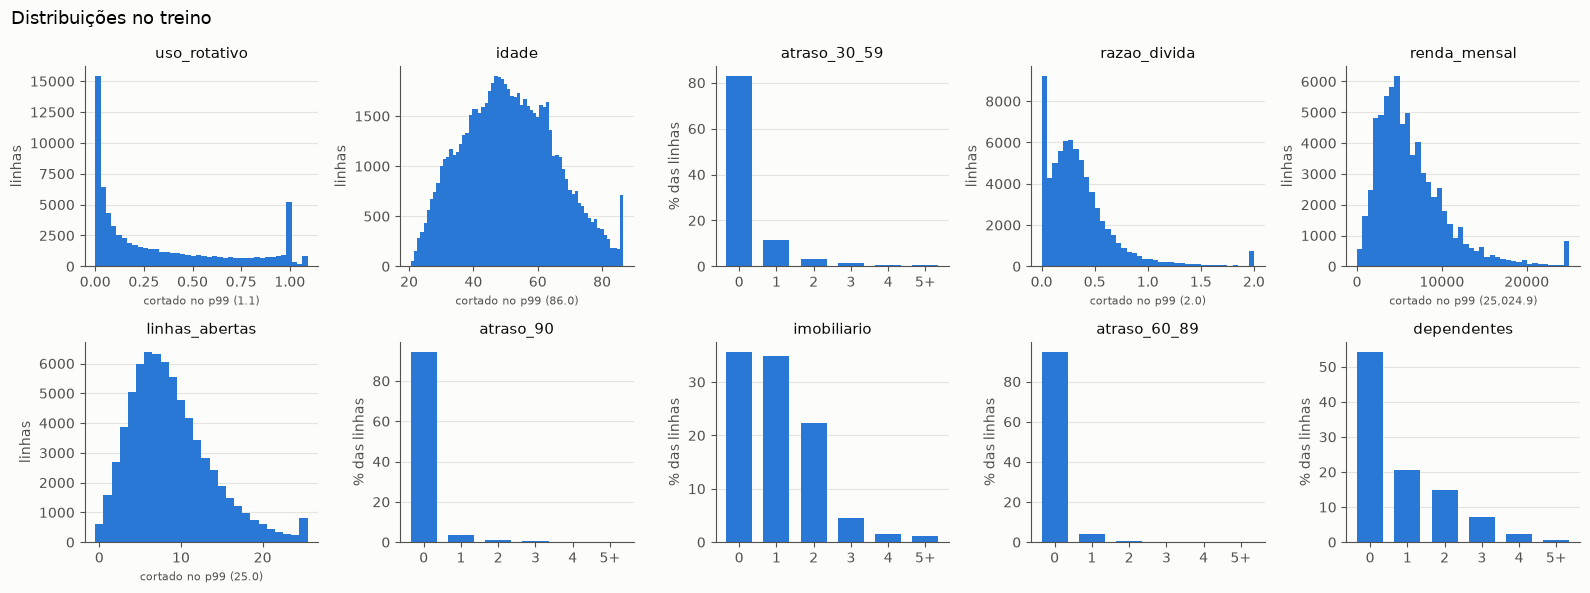

In [15]:
CONTAGENS = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfDependents",
]
fig, eixos = plt.subplots(2, 5, figsize=(16, 6))
for ax, coluna in zip(eixos.flat, FEATURES, strict=True):
    serie = treino[coluna]
    if coluna in CONTAGENS:
        contagem = serie.clip(upper=5).value_counts(normalize=True).sort_index() * 100
        ax.bar(contagem.index, contagem.values, color=AZUL, width=0.7)
        ax.set_xticks(range(6), ["0", "1", "2", "3", "4", "5+"])
        ax.set_ylabel("% das linhas")
    else:
        teto = serie.quantile(0.99)
        inteira = coluna in ("age", "NumberOfOpenCreditLinesAndLoans")
        bins = np.arange(serie.min(), teto + 2) - 0.5 if inteira else 40
        ax.hist(serie.clip(upper=teto), bins=bins, color=AZUL)
        ax.set_ylabel("linhas")
        ax.set_xlabel(f"cortado no p99 ({teto:,.1f})", fontsize=8)
    ax.set_title(NOMES[coluna])
fig.suptitle("Distribuições no treino", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
plt.show()

- **Caudas longas extremas** em `uso_rotativo` e `renda_mensal` (assimetria acima de 100). A
  média de `uso_rotativo` é 6,25 e a mediana 0,18: a média é dominada por poucos valores
  absurdos e não descreve ninguém. Nesta base, resumo é mediana e quantil.
- **Contagens de atraso infladas de zeros**: 83%, 94,5% e 94,9% das pessoas nunca atrasaram
  nas três faixas. Quase toda a informação dessas colunas está em "atrasou ou não".
- **`uso_rotativo` tem um pico em exatamente 1,0**: clientes com o limite inteiro tomado.
- **Idade** vai de 21 a 102 no treino, centrada em 51 anos; poucas pessoas abaixo de 25.
- **Dependentes**: 54% não têm nenhum.
- A barra alta no fim de `renda_mensal` e `linhas_abertas` é o corte no p99, não um pico real.

## 6. Outliers

A regra clássica do boxplot (acima de Q3 + 1,5·IQR) é o ponto de partida, mas ela foi pensada
para distribuições simétricas. A tabela abaixo mostra onde ela funciona e onde engana.

In [16]:
q1, q3 = treino[list(FEATURES)].quantile(0.25), treino[list(FEATURES)].quantile(0.75)
limite = q3 + 1.5 * (q3 - q1)
acima = treino[list(FEATURES)].gt(limite)
outliers = pd.DataFrame(
    {
        "Q1": q1,
        "Q3": q3,
        "limite IQR": limite,
        "linhas acima": acima.sum(),
        "% acima": acima.mean() * 100,
        "inadimplência acima": [treino.loc[acima[c], ALVO].mean() for c in FEATURES],
        "inadimplência abaixo": [treino.loc[~acima[c], ALVO].mean() for c in FEATURES],
    }
).rename(index=NOMES)
display(outliers)

,Q1,Q3,limite IQR,linhas acima,% acima,inadimplência acima,inadimplência abaixo
uso_rotativo,0.0356,0.5774,1.3903,327,0.4622,0.2997,0.0684
idade,41.0000,62.0000,93.5000,40,0.0565,0.0500,0.0694
atraso_30_59,0.0000,0.0000,0.0000,12008,16.9727,0.2014,0.0425
razao_divida,0.1421,0.4708,0.9638,3337,4.7167,0.1262,0.0666
renda_mensal,"3,500.0000","8,333.0000","15,582.5000",2964,4.1895,0.0425,0.0706
linhas_abertas,5.0000,11.0000,20.0000,2115,2.9894,0.0676,0.0695
atraso_90,0.0000,0.0000,0.0000,3864,5.4616,0.4123,0.0496
imobiliario,0.0000,2.0000,5.0000,423,0.5979,0.1797,0.0688
atraso_60_89,0.0000,0.0000,0.0000,3595,5.0813,0.3588,0.0539
dependentes,0.0000,2.0000,5.0000,126,0.1781,0.1429,0.0693


A regra do IQR erra de dois jeitos aqui:

- **Nas contagens infladas de zeros, Q1 = Q3 = 0**, o limite vira 0 e qualquer atraso conta
  como "outlier" — 17% das linhas em `atraso_30_59`. E esses "outliers" são justamente o sinal:
  inadimplência de 20% contra 4% em `atraso_30_59`, de 41% contra 5% em `atraso_90`.
  **Remover outliers por IQR apagaria a informação mais preditiva da base.**
- **Nas caudas longas**, o "outlier" também carrega sinal: quem está acima do limite de renda
  inadimple 4,25%, contra 7,06% abaixo.

Conclusão: nesta base, outlier se decide por **plausibilidade de negócio** ("esse valor é
possível?"), não por regra estatística — o critério das regras da seção 2.4.

### 6.1 `uso_rotativo` acima de 100%

Pela descrição do dicionário, é uma proporção — saldo dividido pelo limite —, então o
esperado seria ficar entre 0 e 1. Nenhuma regra da seção 2.4 cobre esta coluna.

,linhas,inadimplentes,taxa,IC95 inferior,IC95 superior,% da base
RevolvingUtilizationOfUnsecuredLines,,,,,,
0-10%,28470,564,0.0198,0.0183,0.0215,40.2409
10-30%,14019,461,0.0329,0.0301,0.0360,19.8151
30-50%,8082,491,0.0608,0.0558,0.0662,11.4235
50-70%,5863,559,0.0953,0.0881,0.1031,8.2870
70-90%,5140,746,0.1451,0.1358,0.1550,7.2651
90-100%,7513,1457,0.1939,0.1851,0.2030,10.6192
100-150%,1384,554,0.4003,0.3748,0.4263,1.9562
150-200%,112,49,0.4375,0.3492,0.5299,0.1583
200%-10x,63,21,0.3333,0.2295,0.4563,0.0890


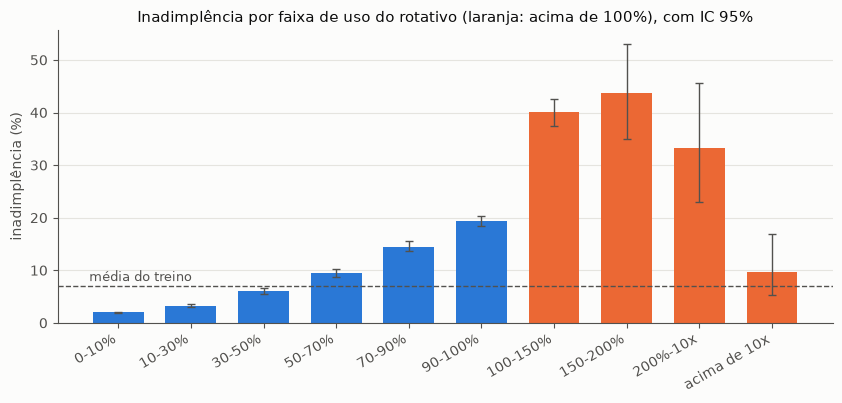

In [17]:
def taxa_por_faixa(frame: pd.DataFrame, faixas: pd.Series) -> pd.DataFrame:
    agrupado = frame.groupby(faixas, observed=True)[ALVO].agg(["size", "sum", "mean"])
    agrupado.columns = ["linhas", "inadimplentes", "taxa"]
    ic = [
        wilson(int(s), int(n))
        for s, n in zip(agrupado["inadimplentes"], agrupado["linhas"], strict=True)
    ]
    agrupado["IC95 inferior"] = [i[0] for i in ic]
    agrupado["IC95 superior"] = [i[1] for i in ic]
    agrupado["% da base"] = agrupado["linhas"] / len(frame) * 100
    return agrupado


cortes = [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0, 1.5, 2, 10, np.inf]
rotulos = [
    "0-10%",
    "10-30%",
    "30-50%",
    "50-70%",
    "70-90%",
    "90-100%",
    "100-150%",
    "150-200%",
    "200%-10x",
    "acima de 10x",
]
faixas_rotativo = pd.cut(
    treino["RevolvingUtilizationOfUnsecuredLines"], cortes, labels=rotulos, include_lowest=True
)
rotativo = taxa_por_faixa(treino, faixas_rotativo)
display(rotativo)

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(rotativo))
cores = [AZUL if i < 6 else LARANJA for i in range(len(rotativo))]
ax.bar(x, rotativo["taxa"] * 100, color=cores, width=0.7)
erro = (
    np.vstack(
        [rotativo["taxa"] - rotativo["IC95 inferior"], rotativo["IC95 superior"] - rotativo["taxa"]]
    )
    * 100
)
ax.errorbar(
    x, rotativo["taxa"] * 100, yerr=erro, fmt="none", ecolor=TINTA_2, capsize=3, linewidth=1
)
ax.axhline(treino[ALVO].mean() * 100, color=TINTA_2, linestyle="--", linewidth=1)
ax.text(-0.4, treino[ALVO].mean() * 100 + 1, "média do treino", color=TINTA_2, fontsize=9)
ax.set_xticks(x, rotulos, rotation=30, ha="right")
ax.set_ylabel("inadimplência (%)")
ax.set_title("Inadimplência por faixa de uso do rotativo (laranja: acima de 100%), com IC 95%")
plt.show()

A curva sobe de forma contínua até 200%: de 2,0% de inadimplência em quem usa até 10% do
limite a cerca de 40% em quem passou do limite (100% a 200%). **Estourar o limite é sinal
real** — esse grupo é 2,1% do treino e inadimple cerca de seis vezes a média.

Acima de 10 vezes o limite, a taxa **volta** para 9,7% (IC de 5,4% a 17,0%), perto da média.
Esses 103 registros não se comportam como "uso extremo", e sim como a população comum. É o
padrão de um erro de unidade — por exemplo, saldo em valor absoluto no lugar da proporção —,
o mesmo tipo de defeito da razão de dívida sem renda.

Implicações:
- **Nenhuma regra da seção 2.4 cobre esta coluna**: um valor de 50.708 passa sem aviso. Ela
  pede uma regra própria, com teto de plausibilidade a calibrar.
- **Cortar em 1,0 seria um erro**: apagaria o segmento de maior risco da base.
- Modelos de árvore lidam com esses valores por partição. A regressão logística
  não: em escala linear, os poucos valores gigantes puxam o coeficiente.

### 6.2 Os extremos da renda

In [18]:
renda = treino["MonthlyIncome"]
extremos = {
    "renda = 0": renda == 0,
    "0 < renda < 500": (renda > 0) & (renda < 500),
    "500 a p99": (renda >= 500) & (renda <= renda.quantile(0.99)),
    "acima do p99": renda > renda.quantile(0.99),
}
tabela_renda = pd.DataFrame(
    {
        nome: {
            "linhas": int(m.sum()),
            "inadimplência": treino.loc[m, ALVO].mean(),
            "razao_divida mediana": treino.loc[m, "DebtRatio"].median(),
        }
        for nome, m in extremos.items()
    }
).T
display(tabela_renda)
print(f"p99 da renda: {renda.quantile(0.99):,.0f} | máximo: {renda.max():,.0f}")

,linhas,inadimplência,razao_divida mediana
renda = 0,92.0000,0.0326,1.0000
0 < renda < 500,245.0000,0.0531,0.8543
500 a p99,"69,704.0000",0.0697,0.2940
acima do p99,708.0000,0.0551,0.1132


p99 da renda: 25,025 | máximo: 3,008,750


Os extremos de renda são pequenos e **nenhum é mais arriscado que a média**: renda igual a zero
(92 linhas, 3,3% de inadimplência) e acima do p99, cerca de 25 mil (708 linhas, 5,5%).

O detalhe que merece atenção é a razão de dívida de quem declara renda zero: mediana
exatamente 1,0. Com denominador zero, o campo não pode ser uma razão de verdade — a fonte
provavelmente substituiu o denominador. É o mesmo defeito da seção 2.3, em escala bem menor, e
a regra de renda ausente não o pega (zero é renda declarada).

## 7. Relação de cada variável com a inadimplência

Para cada variável: a taxa de inadimplência por faixa (decis para as contínuas, valores de 0
a 4+ para as contagens), o **Information Value (IV)** — a medida clássica de poder de
separação em credit scoring — e a **AUC univariada**, que responde "se eu ordenasse os
clientes só por esta variável, quão bem separaria os inadimplentes?" (0,5 = acaso).

In [19]:
def faixas_de(coluna: str, frame: pd.DataFrame) -> pd.Series:
    if coluna in CONTAGENS:
        return frame[coluna].clip(upper=4).astype(int).astype(str).replace("4", "4+")
    return pd.qcut(frame[coluna], 10, duplicates="drop")


def information_value(frame: pd.DataFrame, faixas: pd.Series) -> tuple[float, pd.DataFrame]:
    tabela = pd.crosstab(faixas, frame[ALVO])
    # Suavização de 0,5 para não estourar o log numa faixa sem nenhum inadimplente.
    bons = (tabela[0] + 0.5) / (tabela[0].sum() + 0.5)
    maus = (tabela[1] + 0.5) / (tabela[1].sum() + 0.5)
    woe = np.log(bons / maus)
    return float(((bons - maus) * woe).sum()), pd.DataFrame({"WoE": woe})


def classe_iv(iv: float) -> str:
    for teto, nome in [(0.02, "inútil"), (0.1, "fraco"), (0.3, "médio"), (0.5, "forte")]:
        if iv < teto:
            return nome
    return "muito forte"


linhas = []
for coluna in FEATURES:
    iv, _ = information_value(treino, faixas_de(coluna, treino))
    auc = roc_auc_score(treino[ALVO], treino[coluna])
    linhas.append(
        {
            "variável": NOMES[coluna],
            "IV": iv,
            "poder (IV)": classe_iv(iv),
            "AUC univariada": max(auc, 1 - auc),
            "direção": "maior = mais risco" if auc >= 0.5 else "maior = menos risco",
        }
    )
poder = pd.DataFrame(linhas).sort_values("IV", ascending=False).set_index("variável")
display(poder)

,IV,poder (IV),AUC univariada,direção
variável,,,,
uso_rotativo,1.0330,muito forte,0.7691,maior = mais risco
atraso_90,0.7877,muito forte,0.6461,maior = mais risco
atraso_30_59,0.6914,muito forte,0.6822,maior = mais risco
atraso_60_89,0.5502,muito forte,0.6146,maior = mais risco
idade,0.1935,médio,0.6172,maior = menos risco
razao_divida,0.0916,fraco,0.5700,maior = mais risco
renda_mensal,0.0904,fraco,0.5831,maior = menos risco
linhas_abertas,0.0539,fraco,0.5431,maior = menos risco
imobiliario,0.0535,fraco,0.5344,maior = menos risco


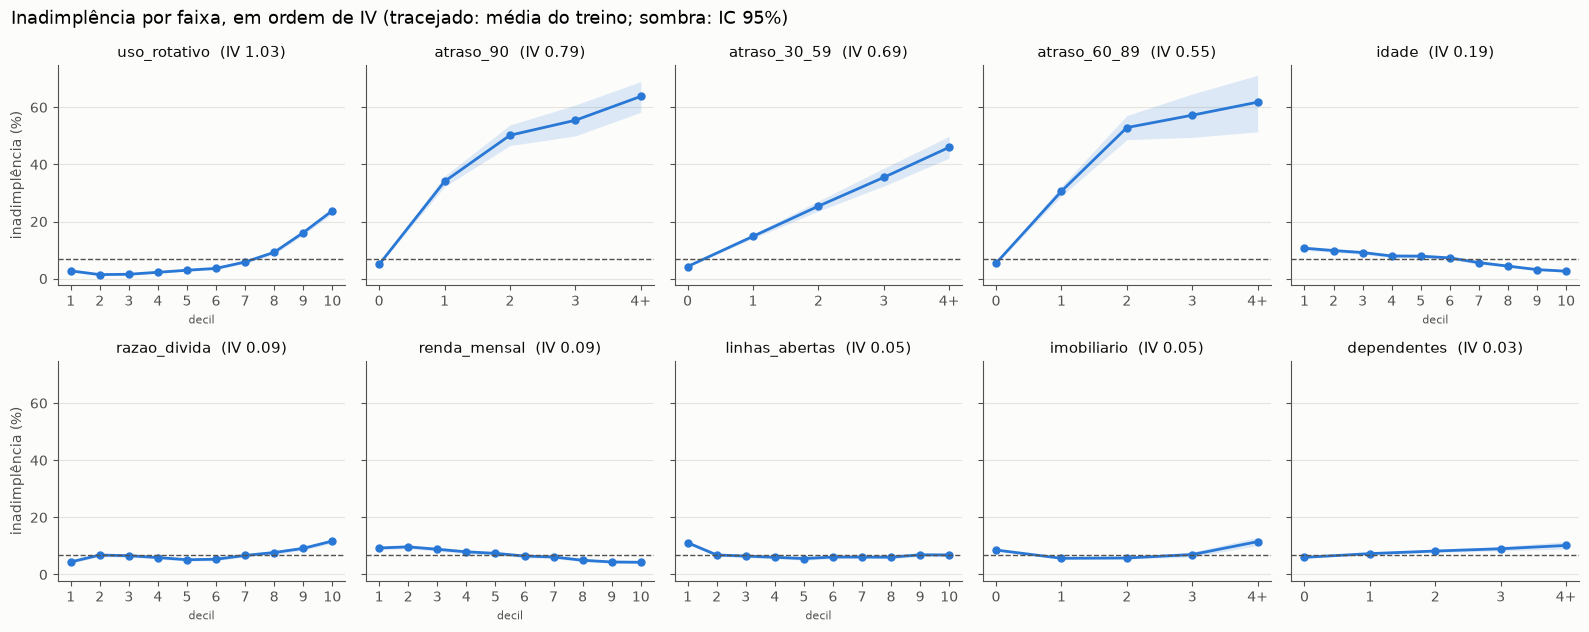

In [20]:
ordem = [c for nome in poder.index for c in FEATURES if NOMES[c] == nome]
media = treino[ALVO].mean() * 100
fig, eixos = plt.subplots(2, 5, figsize=(16, 6.4), sharey=True)
for ax, coluna in zip(eixos.flat, ordem, strict=True):
    tabela = taxa_por_faixa(treino, faixas_de(coluna, treino))
    x = np.arange(len(tabela))
    ax.plot(x, tabela["taxa"] * 100, color=AZUL, linewidth=2, marker="o", markersize=5)
    ax.fill_between(
        x,
        tabela["IC95 inferior"] * 100,
        tabela["IC95 superior"] * 100,
        color=AZUL,
        alpha=0.15,
        linewidth=0,
    )
    ax.axhline(media, color=TINTA_2, linestyle="--", linewidth=1)
    if coluna in CONTAGENS:
        ax.set_xticks(x, tabela.index)
    else:
        ax.set_xticks(x, [str(i + 1) for i in x])
        ax.set_xlabel("decil", fontsize=8)
    ax.set_title(f"{NOMES[coluna]}  (IV {poder.loc[NOMES[coluna], 'IV']:.2f})")
for ax in eixos[:, 0]:
    ax.set_ylabel("inadimplência (%)")
fig.suptitle(
    "Inadimplência por faixa, em ordem de IV (tracejado: média do treino; sombra: IC 95%)",
    x=0.01,
    ha="left",
    fontsize=13,
)
fig.tight_layout()
plt.show()

**O poder preditivo está concentrado em quatro variáveis**: `uso_rotativo` (IV 1,03, AUC
0,77) e as três colunas de atraso (IV entre 0,55 e 0,79). Em credit scoring, IV acima de 0,5
costuma acender alerta de vazamento. Aqui não é vazamento: as variáveis descrevem os dois anos
**anteriores** à decisão e o alvo descreve os dois anos **seguintes** — atraso passado prever
atraso futuro é o mecanismo esperado.

**Idade** tem poder médio (IV 0,19) e cai de forma monotônica: quanto mais velho, menor o
risco.

**Renda e razão de dívida são fracas** (IV 0,09 cada). Isso importa para o problema do
enunciado: se a mudança econômica deslocar sobretudo essas duas variáveis, um modelo treinado
nesta base deve ser pouco sensível a esse deslocamento — uma hipótese a testar quando houver
simulação de drift, não uma conclusão desta análise.

**Três relações não são monotônicas:**
- `linhas_abertas`: quem tem pouquíssimas linhas (decil 1) é o mais arriscado — sem histórico
  de crédito, o *thin file*.
- `imobiliario`: em U — nenhum financiamento ou 4 ou mais são mais arriscados que 1 ou 2.
- `razao_divida`: o decil mais baixo é o menos arriscado e o mais alto, o mais arriscado, com
  um platô no meio.

Uma regressão logística sobre a variável bruta não captura forma de U. Árvores capturam, e uma
logística também capturaria se recebesse as variáveis em faixas (WoE).

## 8. Correlação entre as variáveis

Spearman, não Pearson: ele mede relação monotônica pela ordem dos valores, então não é
dominado pelas caudas longas de renda e razão de dívida.

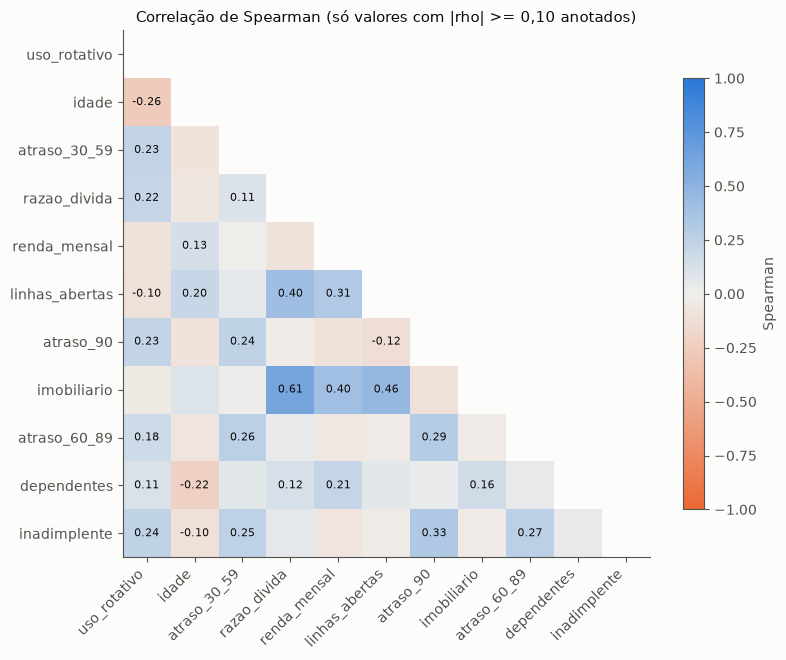

rho  |rho|
level_0        level_1                      
razao_divida   imobiliario     0.6107 0.6107
linhas_abertas imobiliario     0.4598 0.4598
razao_divida   linhas_abertas  0.4035 0.4035
renda_mensal   imobiliario     0.3977 0.3977
               linhas_abertas  0.3149 0.3149
atraso_90      atraso_60_89    0.2926 0.2926
atraso_30_59   atraso_60_89    0.2637 0.2637
uso_rotativo   idade          -0.2599 0.2599

In [21]:
correlacao = treino[[*FEATURES, ALVO]].rename(columns=NOMES).corr(method="spearman")
divergente = LinearSegmentedColormap.from_list("divergente", [LARANJA, "#f0efec", AZUL])
fig, ax = plt.subplots(figsize=(8.5, 7))
triangulo = np.tril(np.ones(correlacao.shape, dtype=bool), k=-1)
imagem = ax.imshow(correlacao.where(triangulo), cmap=divergente, vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(correlacao)), correlacao.columns, rotation=45, ha="right")
ax.set_yticks(range(len(correlacao)), correlacao.index)
for i in range(len(correlacao)):
    for j in range(len(correlacao)):
        valor = correlacao.iloc[i, j]
        if i > j and abs(valor) >= 0.1:
            ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=8, color=TINTA)
fig.colorbar(imagem, ax=ax, shrink=0.8, label="Spearman")
ax.set_title("Correlação de Spearman (só valores com |rho| >= 0,10 anotados)")
plt.show()

pares = (
    correlacao.drop(index=ALVO, columns=ALVO)
    .where(np.triu(np.ones((10, 10), dtype=bool), k=1))
    .stack()
    .rename("rho")
    .reset_index()
)
pares["|rho|"] = pares["rho"].abs()
display(pares.sort_values("|rho|", ascending=False).head(8).set_index(["level_0", "level_1"]))

- **Não há multicolinearidade grave.** A maior correlação entre entradas é 0,61, entre razão
  de dívida e financiamento imobiliário — a parcela do imóvel entra nos pagamentos mensais de
  dívida.
- **Há um bloco de "tamanho da vida financeira"**: imobiliário, linhas abertas, renda e razão
  de dívida se correlacionam entre si (0,31 a 0,61).
- **As três colunas de atraso se correlacionam pouco depois da limpeza** (0,26 a 0,29, contra
  0,98–0,99 com os sentinelas). Carregam informação complementar — vale manter as três.
- **Com o alvo**, a ordem repete a do IV: `atraso_90` (0,33), `atraso_60_89` (0,27),
  `atraso_30_59` (0,25), `uso_rotativo` (0,24).

## 9. Idade: a única variável demográfica

A seção 1 mostrou que idade é a única variável demográfica da base. A pergunta aqui não é só
"a inadimplência muda com a idade?", mas **por qual caminho**: idade se relaciona com o risco
diretamente, ou através de renda, uso de crédito e histórico de atraso?

,linhas,inadimplentes,taxa,IC95 inferior,IC95 superior,% da base
age,,,,,,
18-25,1273,139,0.1092,0.0932,0.1275,1.7993
26-40,16360,1626,0.0994,0.0949,0.1041,23.1240
41-60,33761,2499,0.0740,0.0713,0.0769,47.7194
61+,19355,648,0.0335,0.0310,0.0361,27.3573


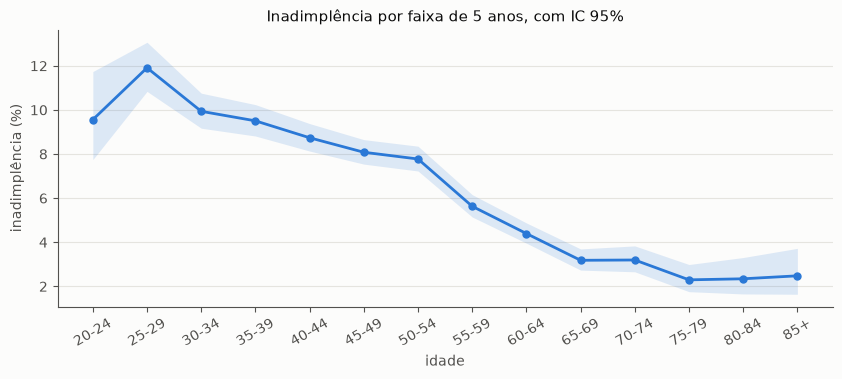

,Spearman com idade,Spearman com o alvo
uso_rotativo,-0.2599,0.2370
dependentes,-0.2178,0.0451
linhas_abertas,0.1993,-0.0381
renda_mensal,0.1322,-0.0732
imobiliario,0.0955,-0.0319
atraso_90,-0.0877,0.3266
atraso_30_59,-0.0787,0.2458
atraso_60_89,-0.0716,0.2653
razao_divida,-0.0666,0.0616


In [22]:
faixas_idade = pd.cut(
    treino["age"], [17, 25, 40, 60, 200], labels=["18-25", "26-40", "41-60", "61+"]
)
display(taxa_por_faixa(treino, faixas_idade))

finas = pd.cut(treino["age"], [*range(20, 90, 5), 200], right=False)
fina = taxa_por_faixa(treino, finas)
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(fina))
ax.plot(x, fina["taxa"] * 100, color=AZUL, linewidth=2, marker="o", markersize=5)
ax.fill_between(
    x, fina["IC95 inferior"] * 100, fina["IC95 superior"] * 100, color=AZUL, alpha=0.15, linewidth=0
)
ax.set_xticks(
    x,
    [f"{int(i.left)}" + ("+" if i.right > 100 else f"-{int(i.right) - 1}") for i in fina.index],
    rotation=30,
)
ax.set_xlabel("idade")
ax.set_ylabel("inadimplência (%)")
ax.set_title("Inadimplência por faixa de 5 anos, com IC 95%")
plt.show()

mediadores = correlacao.loc["idade"].drop(["idade", ALVO]).sort_values(key=abs, ascending=False)
display(
    pd.DataFrame(
        {
            "Spearman com idade": mediadores,
            "Spearman com o alvo": correlacao.loc[mediadores.index, ALVO],
        }
    )
)

- A inadimplência cai com a idade: de 11,9% aos 25–29 anos a 2,3% aos 75–79, com a queda mais
  forte depois dos 55. A faixa de 18–25 tem só 1.273 pessoas no treino (1,8%), por isso o
  intervalo de confiança dela é o mais largo.
- **A idade se relaciona com a variável mais preditiva da base**: Spearman de −0,26 com
  `uso_rotativo` — jovens usam mais rotativo. Com as colunas de atraso, a relação é fraca
  (−0,07 a −0,09).

**A pergunta que isso deixa para a análise causal:** parte do efeito da idade sobre o risco
pode passar por `uso_rotativo` (e por dependentes e renda), e parte pode ser direta — ciclo
de vida, estabilidade. É essa separação que distingue "o modelo penaliza a idade" de "o modelo
usa um comportamento de crédito que difere entre idades". A EDA mostra que os caminhos
existem; medir quanto passa por cada um é trabalho da análise causal.

## 10. Conclusões

### O que a base mostrou

| # | Achado | Evidência | O que fazer com ele |
|---|---|---|---|
| 1 | Renda e dependentes ausentes são **um evento só** | 100% das ausências de dependentes estão entre as de renda (2.1) | não imputar as duas como independentes |
| 2 | Quem não declara renda é um **segmento de menor risco e mais velho** | 5,61% contra 6,95%, IC sem sobreposição; mediana de 57 contra 51 anos (3) | o descarte é viés de seleção; o segmento pede tratamento próprio, e a equidade por idade precisa considerá-lo |
| 3 | Sentinelas 96/98 nas três colunas de atraso, **nas mesmas linhas** | 269 linhas inflam o Pearson de cerca de 0,25 para 0,99 (2.3) | regra de limpeza (2.4) |
| 4 | Razão de dívida sem renda é **outra unidade de medida** | mediana 1.159 contra 0,30 (2.3) | regra de limpeza (2.4) |
| 5 | `uso_rotativo` acima de 100% é **sinal**; acima de 10x parece **erro**, e nenhuma regra cobre a coluna | ~40% de inadimplência entre 100% e 200%; 9,7% acima de 10x (6.1) | regra nova de plausibilidade, sem cortar em 1,0 |
| 6 | A classe é **rara** | 6,94% de inadimplência na base limpa; um modelo constante acerta 93,06% e não identifica ninguém (4) | acurácia não serve; ler AUC-PR contra a prevalência |
| 7 | O poder está em **quatro variáveis** (rotativo e atrasos); renda e razão de dívida são fracas | IV 1,03 / 0,79 / 0,69 / 0,55 contra 0,09 (7) | priorizar essas quatro em qualidade e monitoramento |
| 8 | Relações **não monotônicas** (imobiliário, linhas abertas, razão de dívida) | curvas em U (7) | favorece árvores ou variáveis em faixas (WoE) |
| 9 | Outlier por IQR **apaga sinal** nesta base | "outliers" de atraso com 20% a 41% de inadimplência (6) | decidir outlier por plausibilidade |
| 10 | O risco cai com a idade, e a idade se relaciona com o uso do rotativo | 11,9% aos 25–29 contra 2,3% aos 75–79; Spearman −0,26 (9) | separar efeito direto e mediado na análise causal |
| 11 | Há ruído que as variáveis não explicam | 37 perfis idênticos com desfechos opostos (2.2) | nenhum — é o teto do que a base permite |

### O que a base não permite responder

Medido na seção 1 — o arquivo não tem as colunas que estas perguntas exigiriam:

- **Tempo.** Sem data, não há como validar o modelo fora do período de treino, medir a
  defasagem do rótulo nem observar drift real. Qualquer passagem do tempo terá de ser
  simulada.
- **Custo de cada erro.** Sem valor emprestado, taxa ou margem, o custo de aprovar um
  inadimplente contra o de recusar um bom pagador não é mensurável aqui; ele precisa vir do
  negócio como premissa explícita.
- **Outras variáveis demográficas.** Só há idade: equidade só pode ser medida por idade, e
  variáveis como renda ou dependentes podem carregar sinal de atributos que a base não tem.
- **Como a amostra foi formada.** Nada no arquivo diz quem entrou na base e quem ficou de
  fora antes dela — por exemplo, pedidos recusados no passado. O viés de seleção que esta
  análise mede é só o que a própria limpeza cria (seção 3).

### Hipóteses para a análise causal

- **H-a.** O efeito da idade sobre a inadimplência é, em parte, mediado pelo uso do rotativo
  (seção 9).
- **H-b.** Renda é fraca nesta base (seção 7); um deslocamento nominal de renda, como o que a
  inflação produz, deve mover pouco um modelo treinado aqui.
- **H-c.** Uma mudança na relação entre comportamento e desfecho (*concept drift*) não
  aparece em nenhuma estatística das variáveis de entrada — só no desempenho medido contra o
  rótulo.
- **H-d.** A regra que descarta renda ausente é um mecanismo de seleção correlacionado com
  idade e risco (seção 3): um caminho de viés que não passa pelo modelo.